# Titles-only NLP vs CCAM

Fast path using **headlines only** (no scraped body text).

```bash
python analysis/titles_only/build_corpus.py
python analysis/titles_only/score_lexicons.py
python analysis/titles_only/run_bert_qa.py --per-year 100
python analysis/titles_only/run_climatebert.py --reuse-qa-sample
```

Run this notebook with working directory = `analysis/titles_only/`.

In [7]:
%pip install pandas pyarrow matplotlib seaborn numpy -q

Note: you may need to restart the kernel to use updated packages.


In [8]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "analysis" / "shared"))
from ccam_prepare import apply_recodes, wave_level_outcomes

sns.set_theme(style="whitegrid", context="notebook")
HERE = Path(".")
CCAM_PATH = ROOT / "ccam" / "CCAM_SPSS_Data_2008-2025.csv"

## Method A — lexicon frames on all titles

months: 227  |  titles/month median: 5575


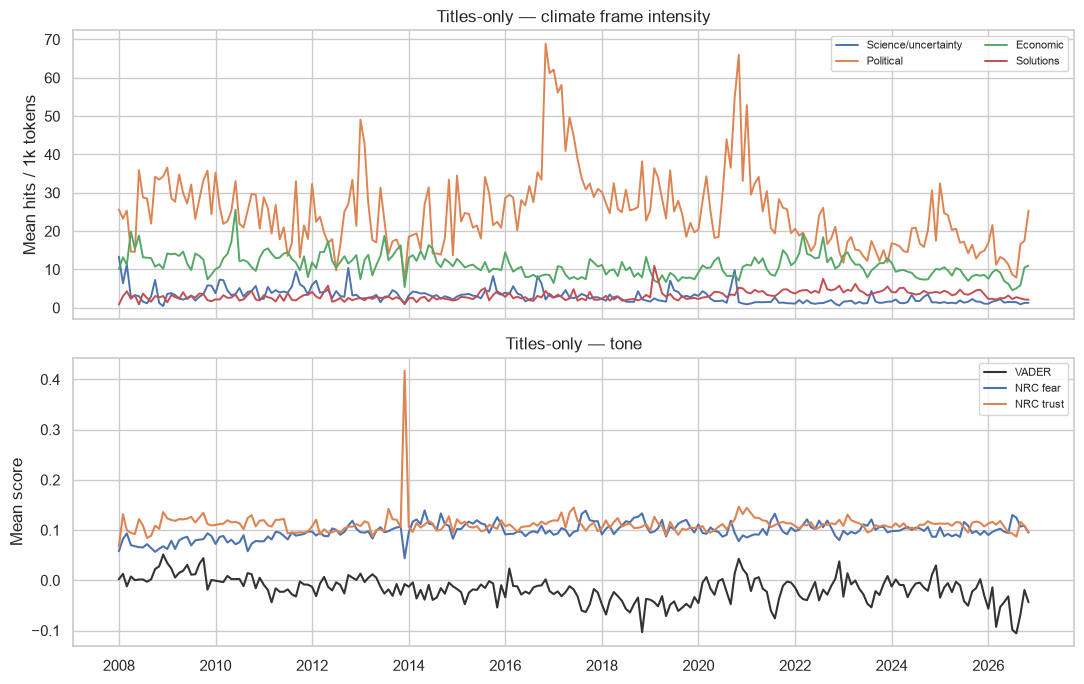

In [9]:
monthly_path = HERE / "titles_lexicon_monthly.parquet"
if not monthly_path.exists():
    raise FileNotFoundError("Run build_corpus.py then score_lexicons.py first.")

monthly = pd.read_parquet(monthly_path)
plot = monthly[monthly["n_titles"] >= 50].copy()
print(f"months: {len(plot):,}  |  titles/month median: {plot['n_titles'].median():.0f}")

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for col, label in [
    ("frame_science_uncertainty", "Science/uncertainty"),
    ("frame_political", "Political"),
    ("frame_economic", "Economic"),
    ("frame_solutions", "Solutions"),
]:
    axes[0].plot(plot["month"], plot[col], label=label, linewidth=1.4)
axes[0].set_ylabel("Mean hits / 1k tokens")
axes[0].set_title("Titles-only — climate frame intensity")
axes[0].legend(ncol=2, fontsize=8)

axes[1].plot(plot["month"], plot["vader_compound"], label="VADER", color="#333")
axes[1].plot(plot["month"], plot["nrc_fear"], label="NRC fear")
axes[1].plot(plot["month"], plot["nrc_trust"], label="NRC trust")
axes[1].set_ylabel("Mean score")
axes[1].set_title("Titles-only — tone")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Load CCAM year series

In [10]:
ccam = apply_recodes(pd.read_csv(CCAM_PATH, low_memory=False))
wave_out = wave_level_outcomes(ccam)

def weighted_share(df, col, values):
    s, w = df[col], df["weight_wave"]
    mask = s.notna() & w.notna() & ~s.astype(str).str.lower().eq("refused")
    if mask.sum() == 0:
        return float("nan")
    return float((w[mask] * s[mask].astype(str).isin(values).astype(float)).sum() / w[mask].sum())

belief_years = []
for year, g in ccam.groupby("year"):
    belief_years.append(
        {
            "year": int(year),
            "happening_yes": weighted_share(g, "happening", {"Yes"}),
            "human_caused": weighted_share(
                g, "cause_recoded", {"Caused mostly by human activities"}
            ),
        }
    )
ccam_year = (
    wave_out.assign(year=wave_out["wave_date"].dt.year)
    .groupby("year", as_index=False)[
        ["worry_high", "harm_US_high", "support_CO2_reg", "priority_cleanenergy_high"]
    ]
    .mean()
    .merge(pd.DataFrame(belief_years), on="year", how="outer")
    .sort_values("year")
)

## Lexicon yearly means vs CCAM

/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_2775/2766696512.py:32: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


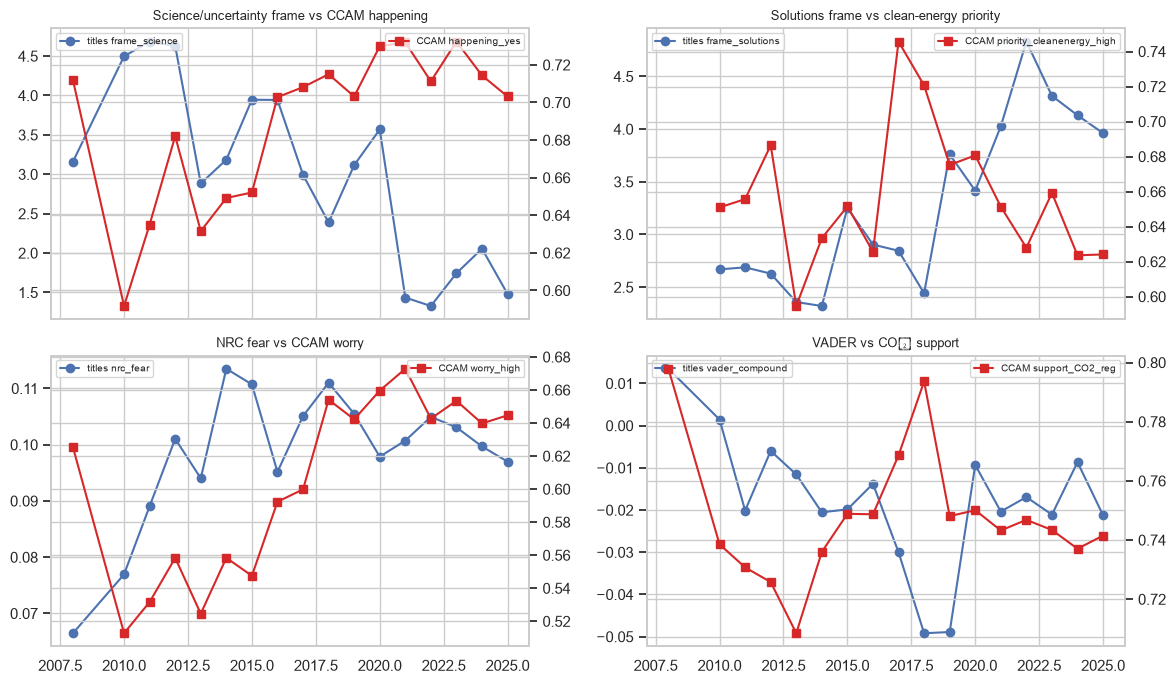

,titles_signal,ccam,pearson_r,n_years
0,frame_science,happening_yes,-0.620,17
1,frame_solutions,priority_cleanenergy_high,-0.219,16
2,nrc_fear,worry_high,0.223,17
3,vader_compound,support_CO2_reg,-0.142,17


In [11]:
scores = pd.read_parquet(HERE / "titles_lexicon_scores.parquet")
lex_year = (
    scores.groupby("year", as_index=False)
    .agg(
        n=("id", "size"),
        frame_solutions=("frame_solutions", "mean"),
        frame_science=("frame_science_uncertainty", "mean"),
        frame_political=("frame_political", "mean"),
        vader_compound=("vader_compound", "mean"),
        nrc_fear=("nrc_fear", "mean"),
    )
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
pairs = [
    ("frame_science", "happening_yes", "Science/uncertainty frame vs CCAM happening"),
    ("frame_solutions", "priority_cleanenergy_high", "Solutions frame vs clean-energy priority"),
    ("nrc_fear", "worry_high", "NRC fear vs CCAM worry"),
    ("vader_compound", "support_CO2_reg", "VADER vs CO₂ support"),
]
corr_rows = []
for ax, (lex_col, ccam_col, title) in zip(axes.ravel(), pairs):
    m = lex_year.merge(ccam_year, on="year", how="inner").dropna(subset=[lex_col, ccam_col])
    ax.plot(m["year"], m[lex_col], marker="o", label=f"titles {lex_col}")
    ax2 = ax.twinx()
    ax2.plot(m["year"], m[ccam_col], marker="s", color="#d62828", label=f"CCAM {ccam_col}")
    ax.set_title(title, fontsize=9)
    ax.legend(loc="upper left", fontsize=7)
    ax2.legend(loc="upper right", fontsize=7)
    r = m[lex_col].corr(m[ccam_col]) if len(m) >= 5 else float("nan")
    corr_rows.append({"titles_signal": lex_col, "ccam": ccam_col, "pearson_r": r, "n_years": len(m)})
plt.tight_layout()
plt.show()
display(pd.DataFrame(corr_rows).style.format({"pearson_r": "{:.3f}"}))

## Method B/C — BERT QA + ClimateBERT (if run)

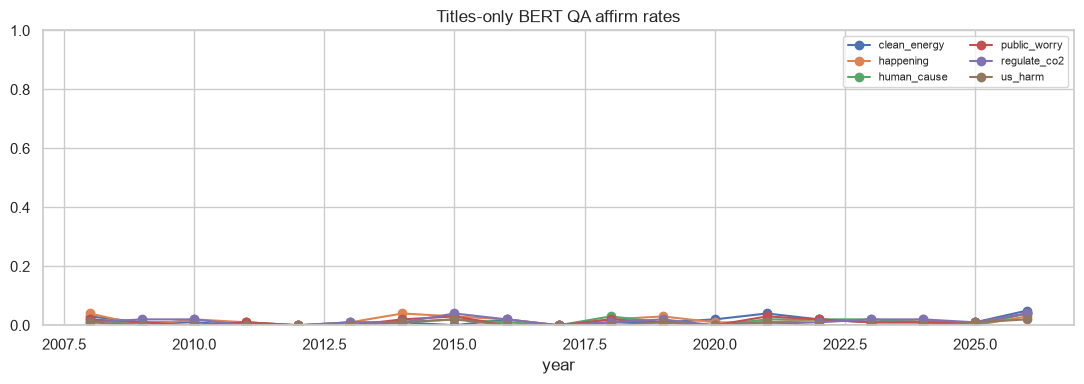

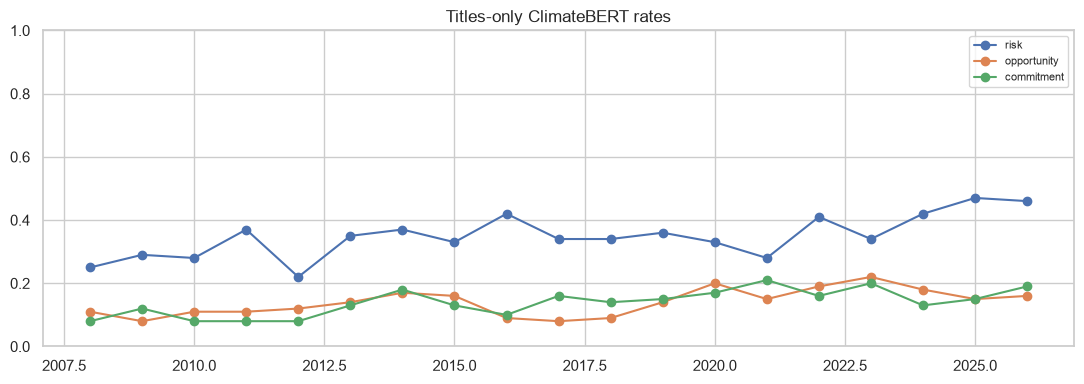

/var/folders/qz/ndsnrxjx0xgbzf96w5x4fx8h0000gn/T/ipykernel_2775/1840891483.py:41: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/lucaslevine/Desktop/project/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


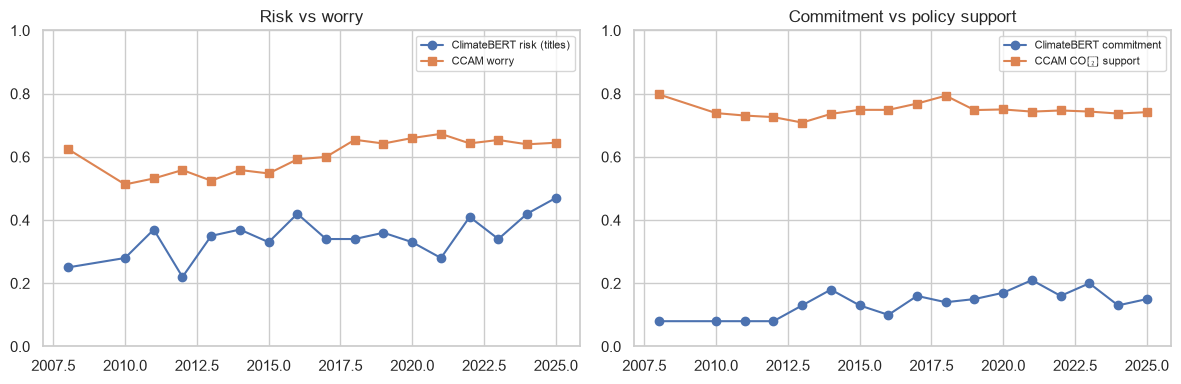

In [12]:
qa_path = HERE / "qa_yearly_affirm_rates.parquet"
cb_path = HERE / "climatebert_yearly_rates.parquet"

if qa_path.exists():
    qa = pd.read_parquet(qa_path)
    pivot = qa.pivot(index="year", columns="item", values="affirm_rate")
    fig, ax = plt.subplots(figsize=(11, 4))
    pivot.plot(ax=ax, marker="o")
    ax.set_ylim(0, 1)
    ax.set_title("Titles-only BERT QA affirm rates")
    ax.legend(fontsize=8, ncol=2)
    plt.tight_layout()
    plt.show()
else:
    print("No QA yearly file — run run_bert_qa.py")

if cb_path.exists():
    yearly = pd.read_parquet(cb_path)
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(yearly["year"], yearly["risk_rate"], marker="o", label="risk")
    ax.plot(yearly["year"], yearly["opportunity_rate"], marker="o", label="opportunity")
    ax.plot(yearly["year"], yearly["commitment_rate"], marker="o", label="commitment")
    ax.set_ylim(0, 1)
    ax.set_title("Titles-only ClimateBERT rates")
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    m = yearly.merge(ccam_year, on="year", how="inner")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(m["year"], m["risk_rate"], marker="o", label="ClimateBERT risk (titles)")
    axes[0].plot(m["year"], m["worry_high"], marker="s", label="CCAM worry")
    axes[0].set_ylim(0, 1)
    axes[0].legend(fontsize=8)
    axes[0].set_title("Risk vs worry")
    axes[1].plot(m["year"], m["commitment_rate"], marker="o", label="ClimateBERT commitment")
    axes[1].plot(m["year"], m["support_CO2_reg"], marker="s", label="CCAM CO₂ support")
    axes[1].set_ylim(0, 1)
    axes[1].legend(fontsize=8)
    axes[1].set_title("Commitment vs policy support")
    plt.tight_layout()
    plt.show()
else:
    print("No ClimateBERT yearly file — run run_climatebert.py")